In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
pd.options.display.max_rows = None
pd.options.display.max_colwidth = 1000
pd.set_option('display.float_format',"{:.2f}".format)
from google.colab import data_table
data_table.enable_dataframe_formatter()
data_table.disable_dataframe_formatter()

In [ ]:

import warnings
warnings.filterwarnings("ignore")
sns.set_style("darkgrid")

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
path="/content/drive/MyDrive/data science practices/Project/archive-1/product_sales_dataset_final.csv"
df=pd.read_csv(path)
df.sample(10)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Order_ID       200000 non-null  int64  
 1   Order_Date     200000 non-null  object 
 2   Customer_Name  200000 non-null  object 
 3   City           200000 non-null  object 
 4   State          200000 non-null  object 
 5   Region         200000 non-null  object 
 6   Country        200000 non-null  object 
 7   Category       200000 non-null  object 
 8   Sub_Category   200000 non-null  object 
 9   Product_Name   200000 non-null  object 
 10  Quantity       200000 non-null  int64  
 11   Unit_Price    200000 non-null  float64
 12   Revenue       200000 non-null  float64
 13   Profit        200000 non-null  float64
dtypes: float64(3), int64(2), object(9)
memory usage: 21.4+ MB
None


In [ ]:
df.describe()
df.isna().sum()
df.head(20)

,Order_ID,Order_Date,Customer_Name,City,State,Region,Country,Category,Sub_Category,Product_Name,Quantity,Unit_Price,Revenue,Profit
0,1,08-23-23,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49
1,2,12-20-24,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.30,297.20,97.09
2,3,01-29-24,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47
3,4,11-29-24,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38
4,5,09-21-23,Catherine Gordon,Baltimore,Maryland,East,United States,Accessories,Bags,Backpack,1,216.63,216.63,42.46
5,6,10-18-24,Brittany Johnson,Boston,Massachusetts,East,United States,Electronics,Home Appliances,Instant Pot,1,701.15,701.15,90.63
6,7,12-11-24,Katie Rodriguez MD,Seattle,Washington,West,United States,Electronics,Wearables,Apple Watch,2,875.34,1750.68,320.37
7,8,05-05-23,John Davis,Tulsa,Oklahoma,South,United States,Clothing & Apparel,Men's Wear,Levi's Jeans,1,329.29,329.29,65.91
8,9,10-25-23,Edward Hicks,Salt Lake City,Utah,West,United States,Clothing & Apparel,Footwear,Timberland Boots,2,115.35,230.70,87.44
9,10,10-15-23,Carrie Cunningham,Fort Smith,Arkansas,South,United States,Electronics,Smartphones,Apple iPhone 14,5,509.51,2547.55,472.90


1- Convert 'Order Date' to datetime format<br>
2- Convert Categorical Columns to 'category' dtype<br>
3- Lowercase all Columns name

#df["Order_Date"]=pd.to_datetime(df["Order_Date"])
df["Order_Date"]=pd.to_datetime(df["Order_Date"],format='%M-%Y-%D')

In [ ]:

categorical_cols=["Region","State","City","Country","Category","Sub_Category"]
for col in categorical_cols:
    df[col]=df[col].astype("category")
df.columns = df.columns.str.lower().str.strip()
df["order_date"]=pd.to_datetime(df["order_date"],errors="coerce")
df.head()
df["cost"]=df["revenue"]-df["profit"]


# Categorising according to Cites and state

In [ ]:
grouped=df.groupby(["state","city"]).agg({
    "revenue":"sum",
    "profit":"sum"
}).sort_values("revenue",ascending=False).reset_index()
grouped=grouped[grouped["revenue"]!=0]
print("cities with best performance \n\n",
    grouped.head(20)[["state","city","revenue"]])
print("\n\ncities with least performance \n\n",
    grouped.tail(20)[["state","city","revenue"]])

cities with best performance 

             state           city    revenue
0         Vermont     Burlington 2367578.63
1   New Hampshire     Manchester 2316261.28
2        New York      Rochester 2312165.68
3        Delaware     Wilmington 2311588.97
4    Rhode Island     Providence 2298465.51
5      New Jersey    Jersey City 2290243.36
6   Massachusetts         Boston 2274264.86
7    Pennsylvania   Philadelphia 2262453.14
8      New Jersey         Newark 2261824.39
9     Connecticut      New Haven 2261371.05
10    Connecticut       Hartford 2254377.39
11   Pennsylvania     Pittsburgh 2233184.14
12       New York  New York City 2229141.59
13       Maryland      Annapolis 2224803.55
14       Delaware          Dover 2203610.72
15  Massachusetts      Worcester 2197189.98
16       Maryland      Baltimore 2190111.48
17        Vermont     Montpelier 2182880.56
18  New Hampshire         Nashua 2172751.59
19          Maine        Augusta 2135780.35


cities with least performance 

          

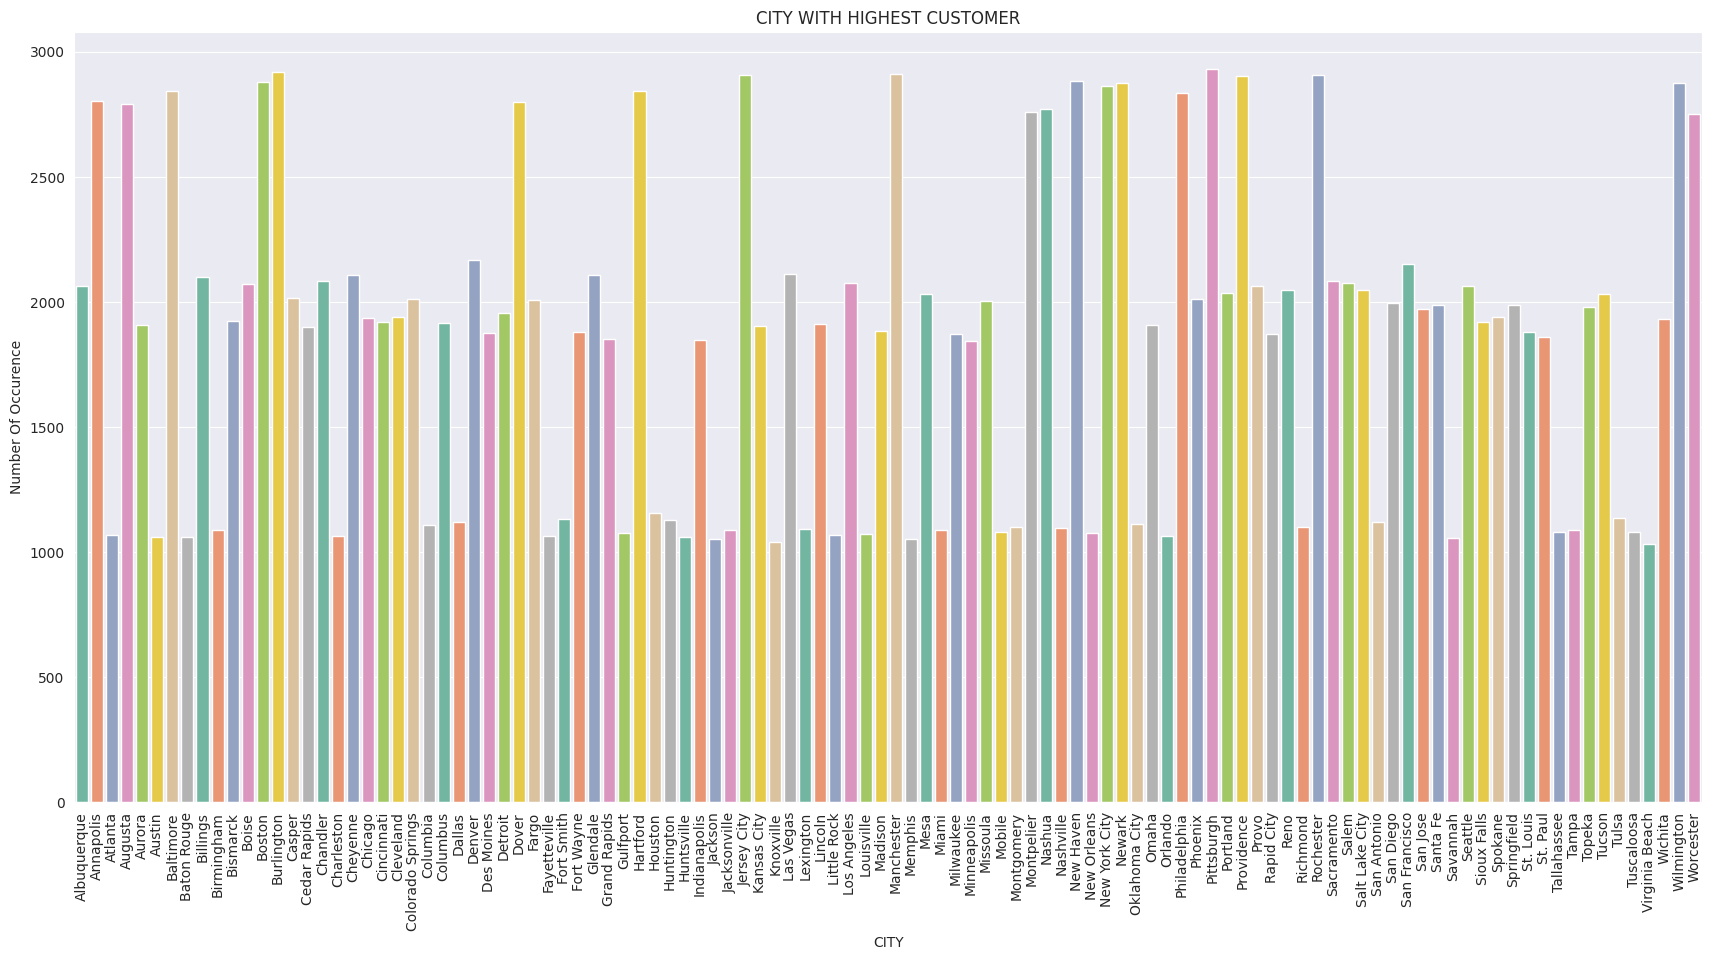

<Figure size 640x480 with 0 Axes>

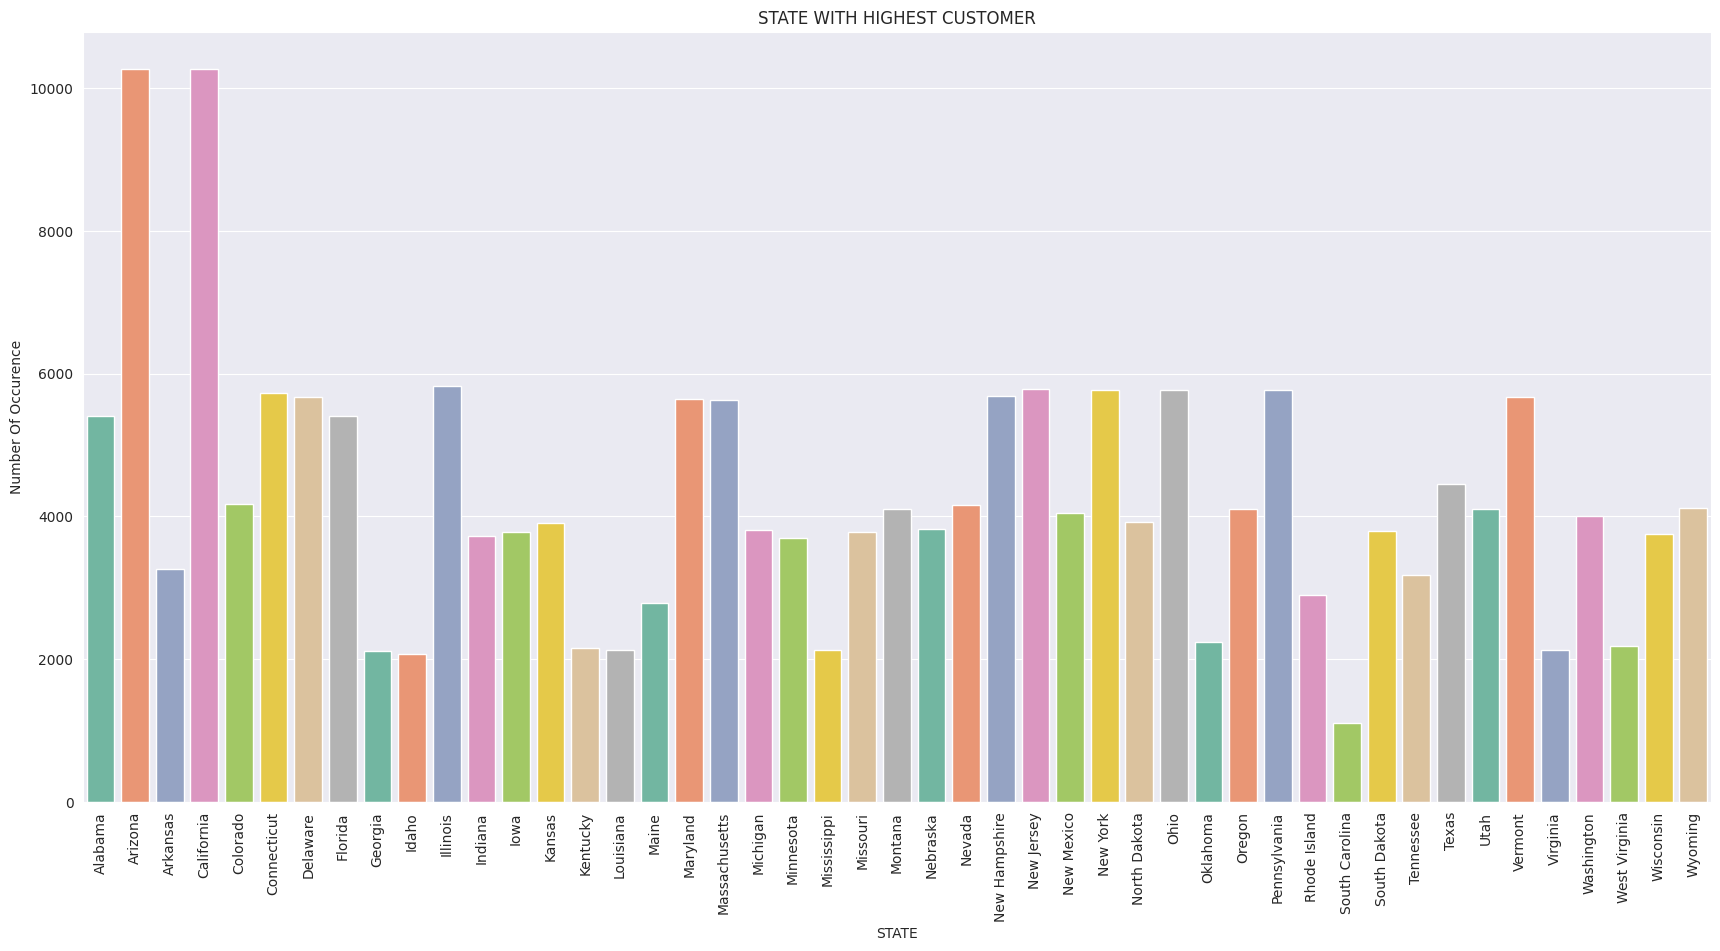

<Figure size 640x480 with 0 Axes>

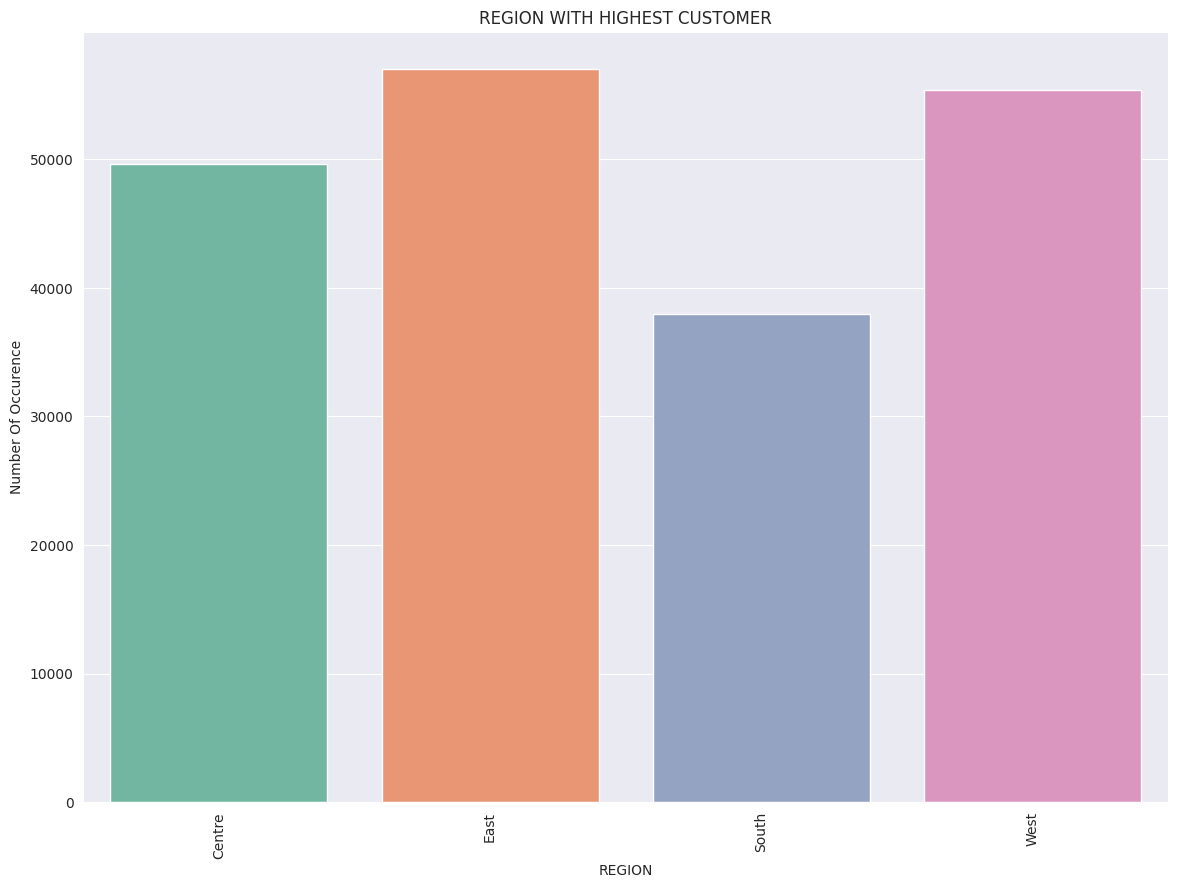

In [ ]:
geo_col=["city","state","region"]
for col in geo_col:
  if col=="region":
    plt.figure(figsize=(14,10))
    plt.title(f"{col.upper()} WITH HIGHEST CUSTOMER")
    sns.countplot(data=df,x=col,palette="Set2")
    plt.xlabel(col.upper())
    plt.ylabel("Number Of Occurence")
    plt.xticks(rotation=90)
    plt.show()

  else:
    plt.figure(figsize=(21,10))
    plt.title(f"{col.upper()} WITH HIGHEST CUSTOMER")
    sns.countplot(data=df,x=col,palette="Set2")
    plt.xlabel(col.upper())
    plt.ylabel("Number Of Occurence")
    plt.xticks(rotation=90)
    plt.show()
    plt.subplots_adjust(hspace=3.8)
plt.show()

In [ ]:
print("\n The count of Customers in each Region ",df.region.value_counts())
print("\n The count of Customers in each City",df.city.value_counts().nlargest(10))
df["state"].value_counts().nlargest(10)


 The count of Customers in each Region  region
East      57034
West      55428
Centre    49603
South     37935
Name: count, dtype: int64

 The count of Customers in each City city
Pittsburgh     2932
Burlington     2920
Manchester     2912
Jersey City    2905
Rochester      2905
Providence     2901
New Haven      2882
Boston         2878
Newark         2875
Wilmington     2874
Name: count, dtype: int64


,count
state,
California,10272
Arizona,10262
Illinois,5832
New Jersey,5780
Ohio,5776
New York,5766
Pennsylvania,5765
Connecticut,5726
New Hampshire,5682


Based on this graph it shows

1.  the east region have the highest purchased number with 57034 numbers of customers
2.  the california state have the highest purchased number with 	10272 numbers of customers  and arizona leading second
3.  the pittsburgh city have the highest purchased number with 	2932 numbers of customers  and Burlington leading second




In [ ]:
df.loc[df["city"]=="Burlington"][["region","state","city"]]

,region,state,city
66,East,Vermont,Burlington
183,East,Vermont,Burlington
195,East,Vermont,Burlington
351,East,Vermont,Burlington
472,East,Vermont,Burlington
492,East,Vermont,Burlington
513,East,Vermont,Burlington
533,East,Vermont,Burlington
548,East,Vermont,Burlington
555,East,Vermont,Burlington


In [ ]:
# to check the total profit generated
x=grouped["profit"].sum()
print("total Profit Generated for the year range \n",x)
# top preforming cities based on profit

y=grouped.nlargest(10,"profit")[["state","city","profit"]]
print("total Profit Generated for the year range \n",y)

total Profit Generated for the year range 
 31548608.13
total Profit Generated for the year range 
             state         city    profit
2        New York    Rochester 478264.38
5      New Jersey  Jersey City 474695.38
1   New Hampshire   Manchester 472307.61
0         Vermont   Burlington 471284.69
9     Connecticut    New Haven 470819.19
4    Rhode Island   Providence 470286.75
13       Maryland    Annapolis 467509.16
10    Connecticut     Hartford 465285.77
11   Pennsylvania   Pittsburgh 462972.49
3        Delaware   Wilmington 462681.40


Checking the revenue been generated

region
Centre   36081894.34
East     44980048.22
South    25102960.64
West     36242841.73
Name: revenue, dtype: float64
142407744.93


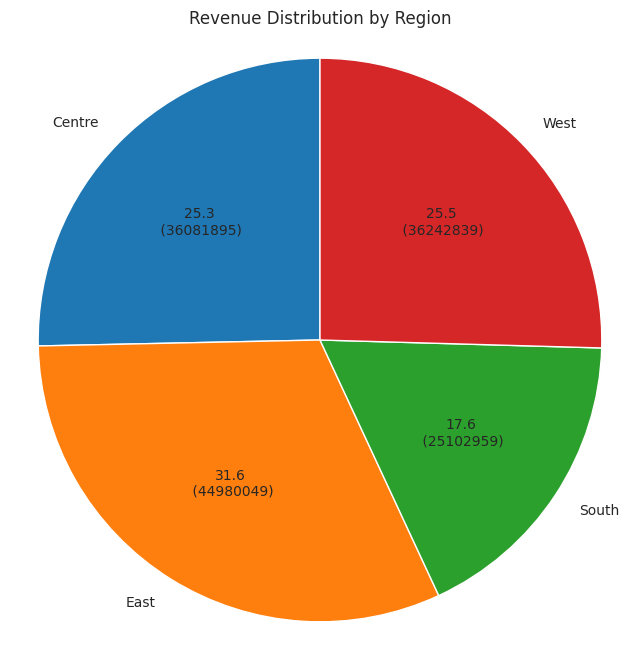

In [ ]:

# Aggregate revenue by region for a meaningful pie chart
region_revenue = df.groupby('region')['revenue'].sum()
print(region_revenue)
total=region_revenue.sum()
print(total)
# Create a pie chart
def format_label(p):
  return f"{p:.1f}%\n({p/100*total:.0f})"
plt.figure(figsize=(8, 8)) # Set figure size for better readability
plt.pie(region_revenue, labels=region_revenue.index, autopct=lambda p :f'{p:.1f}\n ({p/100*total:.0f})', startangle=90)
#plt.pie(region_revenue, labels=region_revenue.index, autopct= format_label, startangle=90)
plt.title('Revenue Distribution by Region')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

The pie chart show that the east has the highest generated revenue and south has the least

['city', 'state', 'region']
           state          city    revenue    profit
0        Vermont    Burlington 2367578.63 471284.69
1  New Hampshire    Manchester 2316261.28 472307.61
2       New York     Rochester 2312165.68 478264.38
3       Delaware    Wilmington 2311588.97 462681.40
4   Rhode Island    Providence 2298465.51 470286.75
5     New Jersey   Jersey City 2290243.36 474695.38
6  Massachusetts        Boston 2274264.86 461176.77
7   Pennsylvania  Philadelphia 2262453.14 461397.04
8     New Jersey        Newark 2261824.39 459068.58
9    Connecticut     New Haven 2261371.05 470819.19


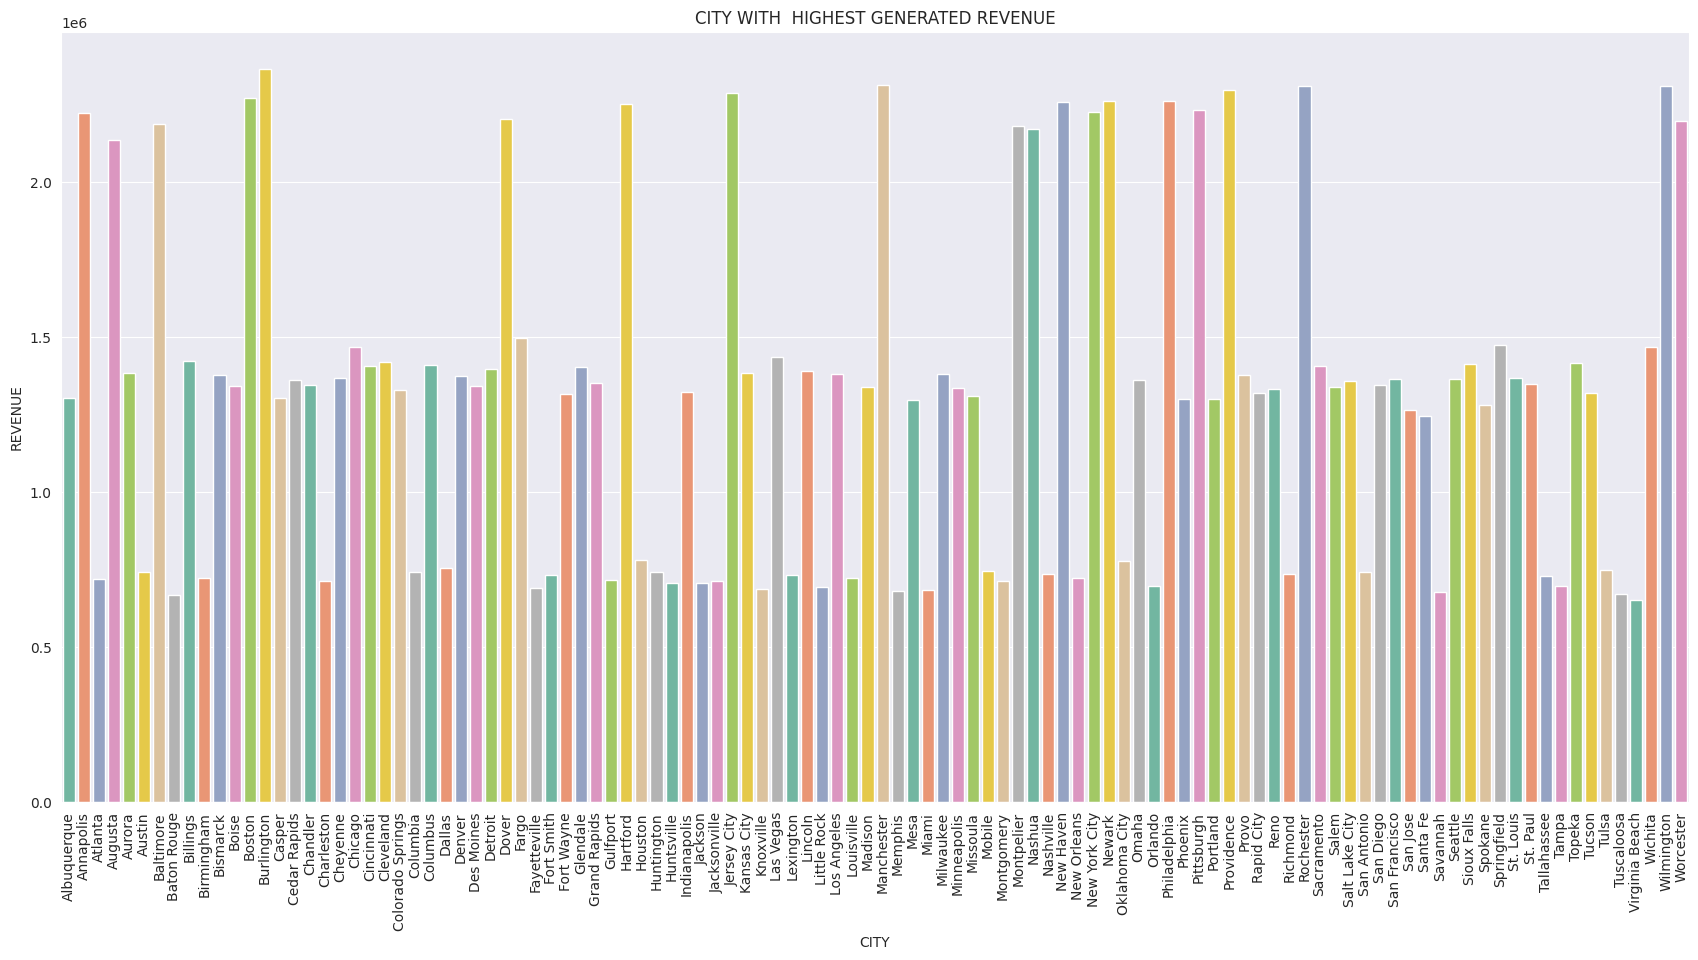

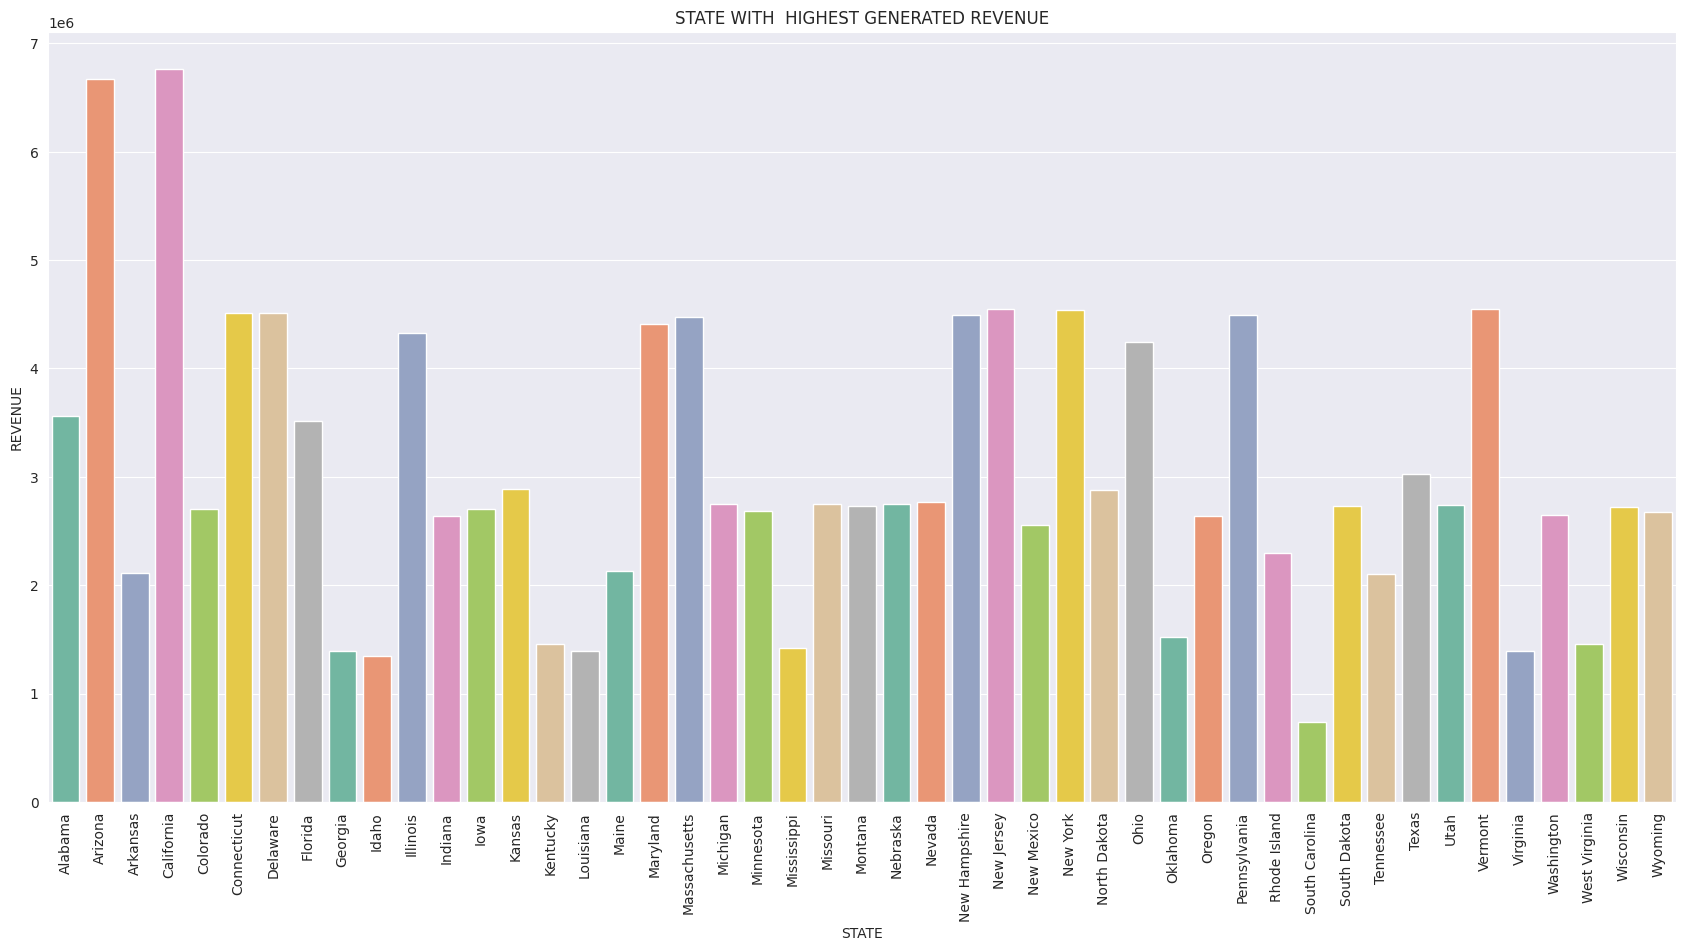

In [ ]:
print(geo_col)
revenue_by_state= df.groupby("state")["revenue"].sum().sort_values(ascending=False)
#print(revenue_by_state)
x=revenue_by_state.index
print(grouped.head(10))
for col in geo_col:
  if col=="region":
    pass
  elif col=="state":
    plt.figure(figsize=(21,10))
    plt.title(f"{col.upper()} WITH  HIGHEST GENERATED REVENUE")
    sns.barplot(x=x,y=revenue_by_state,palette="Set2")
    plt.xlabel(col.upper())
    plt.ylabel("REVENUE")
    plt.xticks(rotation=90)
    plt.subplots_adjust(hspace=3.8)
    plt.show()
  elif col=="city":
    plt.figure(figsize=(21,10))
    plt.title(f"{col.upper()} WITH  HIGHEST GENERATED REVENUE")
    sns.barplot(data=grouped,x=col,y="revenue",palette="Set2")
    plt.xlabel(col.upper())
    plt.ylabel("REVENUE")
    plt.xticks(rotation=90)
    plt.subplots_adjust(hspace=3.8)
    plt.show()
  else:
    pass

In [ ]:
grouped.head(20)
print("Cities with most revenue generated",grouped.loc[0:10, ["city","revenue"]])
print(df.groupby("state")["revenue"].sum().nlargest(10))

Cities with most revenue generated             city    revenue
0     Burlington 2367578.63
1     Manchester 2316261.28
2      Rochester 2312165.68
3     Wilmington 2311588.97
4     Providence 2298465.51
5    Jersey City 2290243.36
6         Boston 2274264.86
7   Philadelphia 2262453.14
8         Newark 2261824.39
9      New Haven 2261371.05
10      Hartford 2254377.39
state
California      6766728.65
Arizona         6668187.20
New Jersey      4552067.75
Vermont         4550459.19
New York        4541307.27
Connecticut     4515748.44
Delaware        4515199.69
Pennsylvania    4495637.28
New Hampshire   4489012.87
Massachusetts   4471454.84
Name: revenue, dtype: float64


The top 10 city that generated the higher Revenue are
             city    revenue
1.    Burlington =2367578.63
2.    Manchester= 2316261.28
3.    Rochester= 2312165.68
4.    Wilmington =2311588.97
5.    Providence =2298465.51
6.    Jersey City= 2290243.36
7.    Boston= 2274264.86
8.    Philadelphia =2262453.14
9.    Newark= 2261824.39
10.   New Haven= 2261371.05







# customer categorization

In [ ]:
raw_id=(
    df["customer_name"].str.upper()+"_" + df["city"].str.upper()
)
df["customer_id"]=raw_id.astype("category").cat.codes
df.head()

,order_id,order_date,customer_name,city,state,region,country,category,sub_category,product_name,quantity,unit_price,revenue,profit,cost,customer_id
0,1,2023-08-23,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49,381.54,19699
1,2,2024-12-20,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.30,297.20,97.09,200.11,77067
2,3,2024-01-29,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47,42.72,178965
3,4,2024-11-29,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38,397.54,186900
4,5,2023-09-21,Catherine Gordon,Baltimore,Maryland,East,United States,Accessories,Bags,Backpack,1,216.63,216.63,42.46,174.17,30107


In [ ]:
print(df.duplicated().sum())
df.drop(columns="country")
df.head()

0


,order_id,order_date,customer_name,city,state,region,country,category,sub_category,product_name,quantity,unit_price,revenue,profit,cost,customer_id
0,1,2023-08-23,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49,381.54,19699
1,2,2024-12-20,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.30,297.20,97.09,200.11,77067
2,3,2024-01-29,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47,42.72,178965
3,4,2024-11-29,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38,397.54,186900
4,5,2023-09-21,Catherine Gordon,Baltimore,Maryland,East,United States,Accessories,Bags,Backpack,1,216.63,216.63,42.46,174.17,30107


In [ ]:
n_col=df.select_dtypes(include="number").columns.to_list()
n_col

['order_id',
 'quantity',
 'unit_price',
 'revenue',
 'profit',
 'cost',
 'customer_id']